In [115]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [116]:
df_customers = pd.read_csv("Datasets/customers.csv")
df_loans = pd.read_csv("Datasets/loans.csv")
df_bureau = pd.read_csv("Datasets/bureau_data.csv")

In [117]:
print(df_customers.shape, df_loans.shape, df_bureau.shape)

(50000, 12) (50000, 15) (50000, 8)


In [118]:
df_customers.sample(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
29416,C29417,41,M,Married,Salaried,201000,3,Mortgage,20,Mumbai,Maharashtra,400001
2554,C02555,31,M,Married,Salaried,4106000,3,Rented,30,Mumbai,Maharashtra,400001
16135,C16136,40,M,Married,Salaried,829000,3,Owned,13,Ahmedabad,Gujarat,380001


In [119]:
df_bureau.sample(3)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
3152,C03153,4,0,132,0,0,9,71
5306,C05307,2,2,90,12,69,7,94
24879,C24880,1,1,36,0,0,6,62


In [120]:
df_loans.sample(3)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
45189,L45190,C45190,Auto,Secured,2513000,2060000,41200.000,370800,1648000,20,1483199,1136470,2024-01-29,2024-02-25,False
29083,L29084,C29084,Home,Secured,2436000,2212000,44240.000,398160,1769600,47,388220,301639,2022-06-20,2022-07-04,False
25232,L25233,C25233,Home,Secured,5770000,4991000,99820.000,898380,3992800,35,748360,737006,2022-01-30,2022-02-17,False


In [121]:
df = pd.merge(df_bureau, df_customers, on="cust_id")
df = pd.merge(df, df_loans, on= "cust_id")
df.head(3)
print(df.shape)

(50000, 33)


In [122]:
df["default"].value_counts()

default
False    45703
True      4297
Name: count, dtype: int64

In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  object 
 1   number_of_open_accounts      50000 non-null  int64  
 2   number_of_closed_accounts    50000 non-null  int64  
 3   total_loan_months            50000 non-null  int64  
 4   delinquent_months            50000 non-null  int64  
 5   total_dpd                    50000 non-null  int64  
 6   enquiry_count                50000 non-null  int64  
 7   credit_utilization_ratio     50000 non-null  int64  
 8   age                          50000 non-null  int64  
 9   gender                       50000 non-null  object 
 10  marital_status               50000 non-null  object 
 11  employment_status            50000 non-null  object 
 12  income                       50000 non-null  int64  
 13  number_of_depend

In [124]:
df["default"] = df["default"].astype(int)

In [125]:
df.sample(3)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
18861,C18862,2,0,102,0,0,7,34,50,M,...,1730000,34600.000,311400,1384000,8,1245599,759528,2021-06-12,2021-07-06,0
16868,C16869,1,2,24,19,116,3,89,44,F,...,1610000,32200.000,289800,1288000,22,921900,367626,2021-03-31,2021-04-23,1
13398,C13399,4,0,88,0,0,5,56,34,M,...,1464000,29280.000,263520,1171200,11,1054079,740680,2020-11-24,2020-12-04,0


### Handling Data Leakage

In [126]:
X = df.drop("default", axis = 1)
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [127]:
X_train[:2]

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt
38094,C38095,4,0,115,0,0,9,42,44,F,...,838000,707000,14140.000,127260,565600,37,150837,117407,2023-05-15,2023-06-13
40624,C40625,2,2,87,0,0,7,8,39,M,...,5000000,4538000,90760.000,816840,3630400,21,3267359,3799236,2023-08-15,2023-08-22


In [128]:
y_train[:2]

38094    0
40624    0
Name: default, dtype: int64

In [129]:
df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.concat([X_test, y_test], axis = 1)
print(df_train.shape)

df_train.head(3)


(35000, 33)


,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
38094,C38095,4,0,115,0,0,9,42,44,F,...,707000,14140.000,127260,565600,37,150837,117407,2023-05-15,2023-06-13,0
40624,C40625,2,2,87,0,0,7,8,39,M,...,4538000,90760.000,816840,3630400,21,3267359,3799236,2023-08-15,2023-08-22,0
49425,C49426,4,1,178,0,0,7,27,37,F,...,6011000,120220.000,1081980,4808800,27,2718477,1855781,2024-07-01,2024-07-05,0


In [130]:
print(df_test.shape)

(15000, 33)


<h3 align="center" style="color:blue">Data Cleaning</h3>

### Handling null values

In [131]:
df_train.isnull().sum()

cust_id                         0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd                       0
enquiry_count                   0
credit_utilization_ratio        0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 42
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_a

In [132]:
df_train["residence_type"].unique()

array(['Mortgage', 'Owned', 'Rented', nan], dtype=object)

In [133]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values = np.nan, strategy="most_frequent")
df_train[["residence_type"]] = imputer.fit_transform(df_train[["residence_type"]])

In [134]:
df_train.residence_type.unique()

array(['Mortgage', 'Owned', 'Rented'], dtype=object)

In [135]:
df_test[["residence_type"]] = imputer.fit_transform(df_test[["residence_type"]])
print(df_test.residence_type.unique())

['Owned' 'Rented' 'Mortgage']


### Duplicated

In [136]:
df_train.duplicated().sum()

np.int64(0)

In [137]:
df_test.duplicated().sum()

np.int64(0)

### Handling outlier

In [138]:
df_train.columns

Index(['cust_id', 'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default'],
      dtype='object')

In [139]:
df_train.describe()

,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,income,number_of_dependants,...,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,default
count,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,...,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000,35000.000
mean,2.497,0.997,76.049,4.889,26.919,5.006,43.360,39.591,2636609.486,1.943,...,418905.429,4699666.657,3997926.257,80599.425,719626.726,3198341.006,25.897,1336119.061,988188.616,0.086
std,1.117,0.815,43.725,5.861,32.901,2.025,29.388,9.856,2623234.634,1.536,...,168888.383,6265691.053,5387224.000,120660.960,969700.320,4309779.200,12.431,1212376.274,1046263.950,0.280
min,1.000,0.000,1.000,0.000,0.000,1.000,0.000,18.000,0.000,0.000,...,110001.000,0.000,0.000,0.000,0.000,0.000,6.000,-1.000,0.000,0.000
25%,1.000,0.000,42.000,0.000,0.000,4.000,18.000,33.000,803000.000,0.000,...,302001.000,1135000.000,960000.000,19200.000,172800.000,768000.000,16.000,425519.000,286541.500,0.000
50%,2.000,1.000,71.000,3.000,14.000,5.000,39.000,40.000,1887000.000,2.000,...,400001.000,2652000.000,2236000.000,44740.000,402480.000,1788800.000,24.000,1002959.000,667902.500,0.000
75%,3.000,2.000,107.000,9.000,46.000,6.000,67.000,46.000,3334000.000,3.000,...,560001.000,5164000.000,4600000.000,92040.000,828000.000,3680000.000,35.000,1788849.250,1236398.750,0.000
max,4.000,2.000,223.000,24.000,171.000,9.000,99.000,70.000,11999000.000,5.000,...,700001.000,52175000.000,47667000.000,5698029.901,8580060.000,38133600.000,59.000,5000000.000,7846643.000,1.000


In [140]:
columns_continuous = ['age', 'income', 'number_of_dependants', 'years_at_current_address', 
                      'sanction_amount', 'loan_amount', 'processing_fee', 'gst', 'net_disbursement', 
                      'loan_tenure_months','principal_outstanding', 'bank_balance_at_application',
                      'number_of_open_accounts','number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
                       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

columns_categorical = ['gender', 'marital_status', 'employment_status', 'residence_type', 'city', 
                       'state', 'zipcode', 'loan_purpose', 'loan_type', 'default']

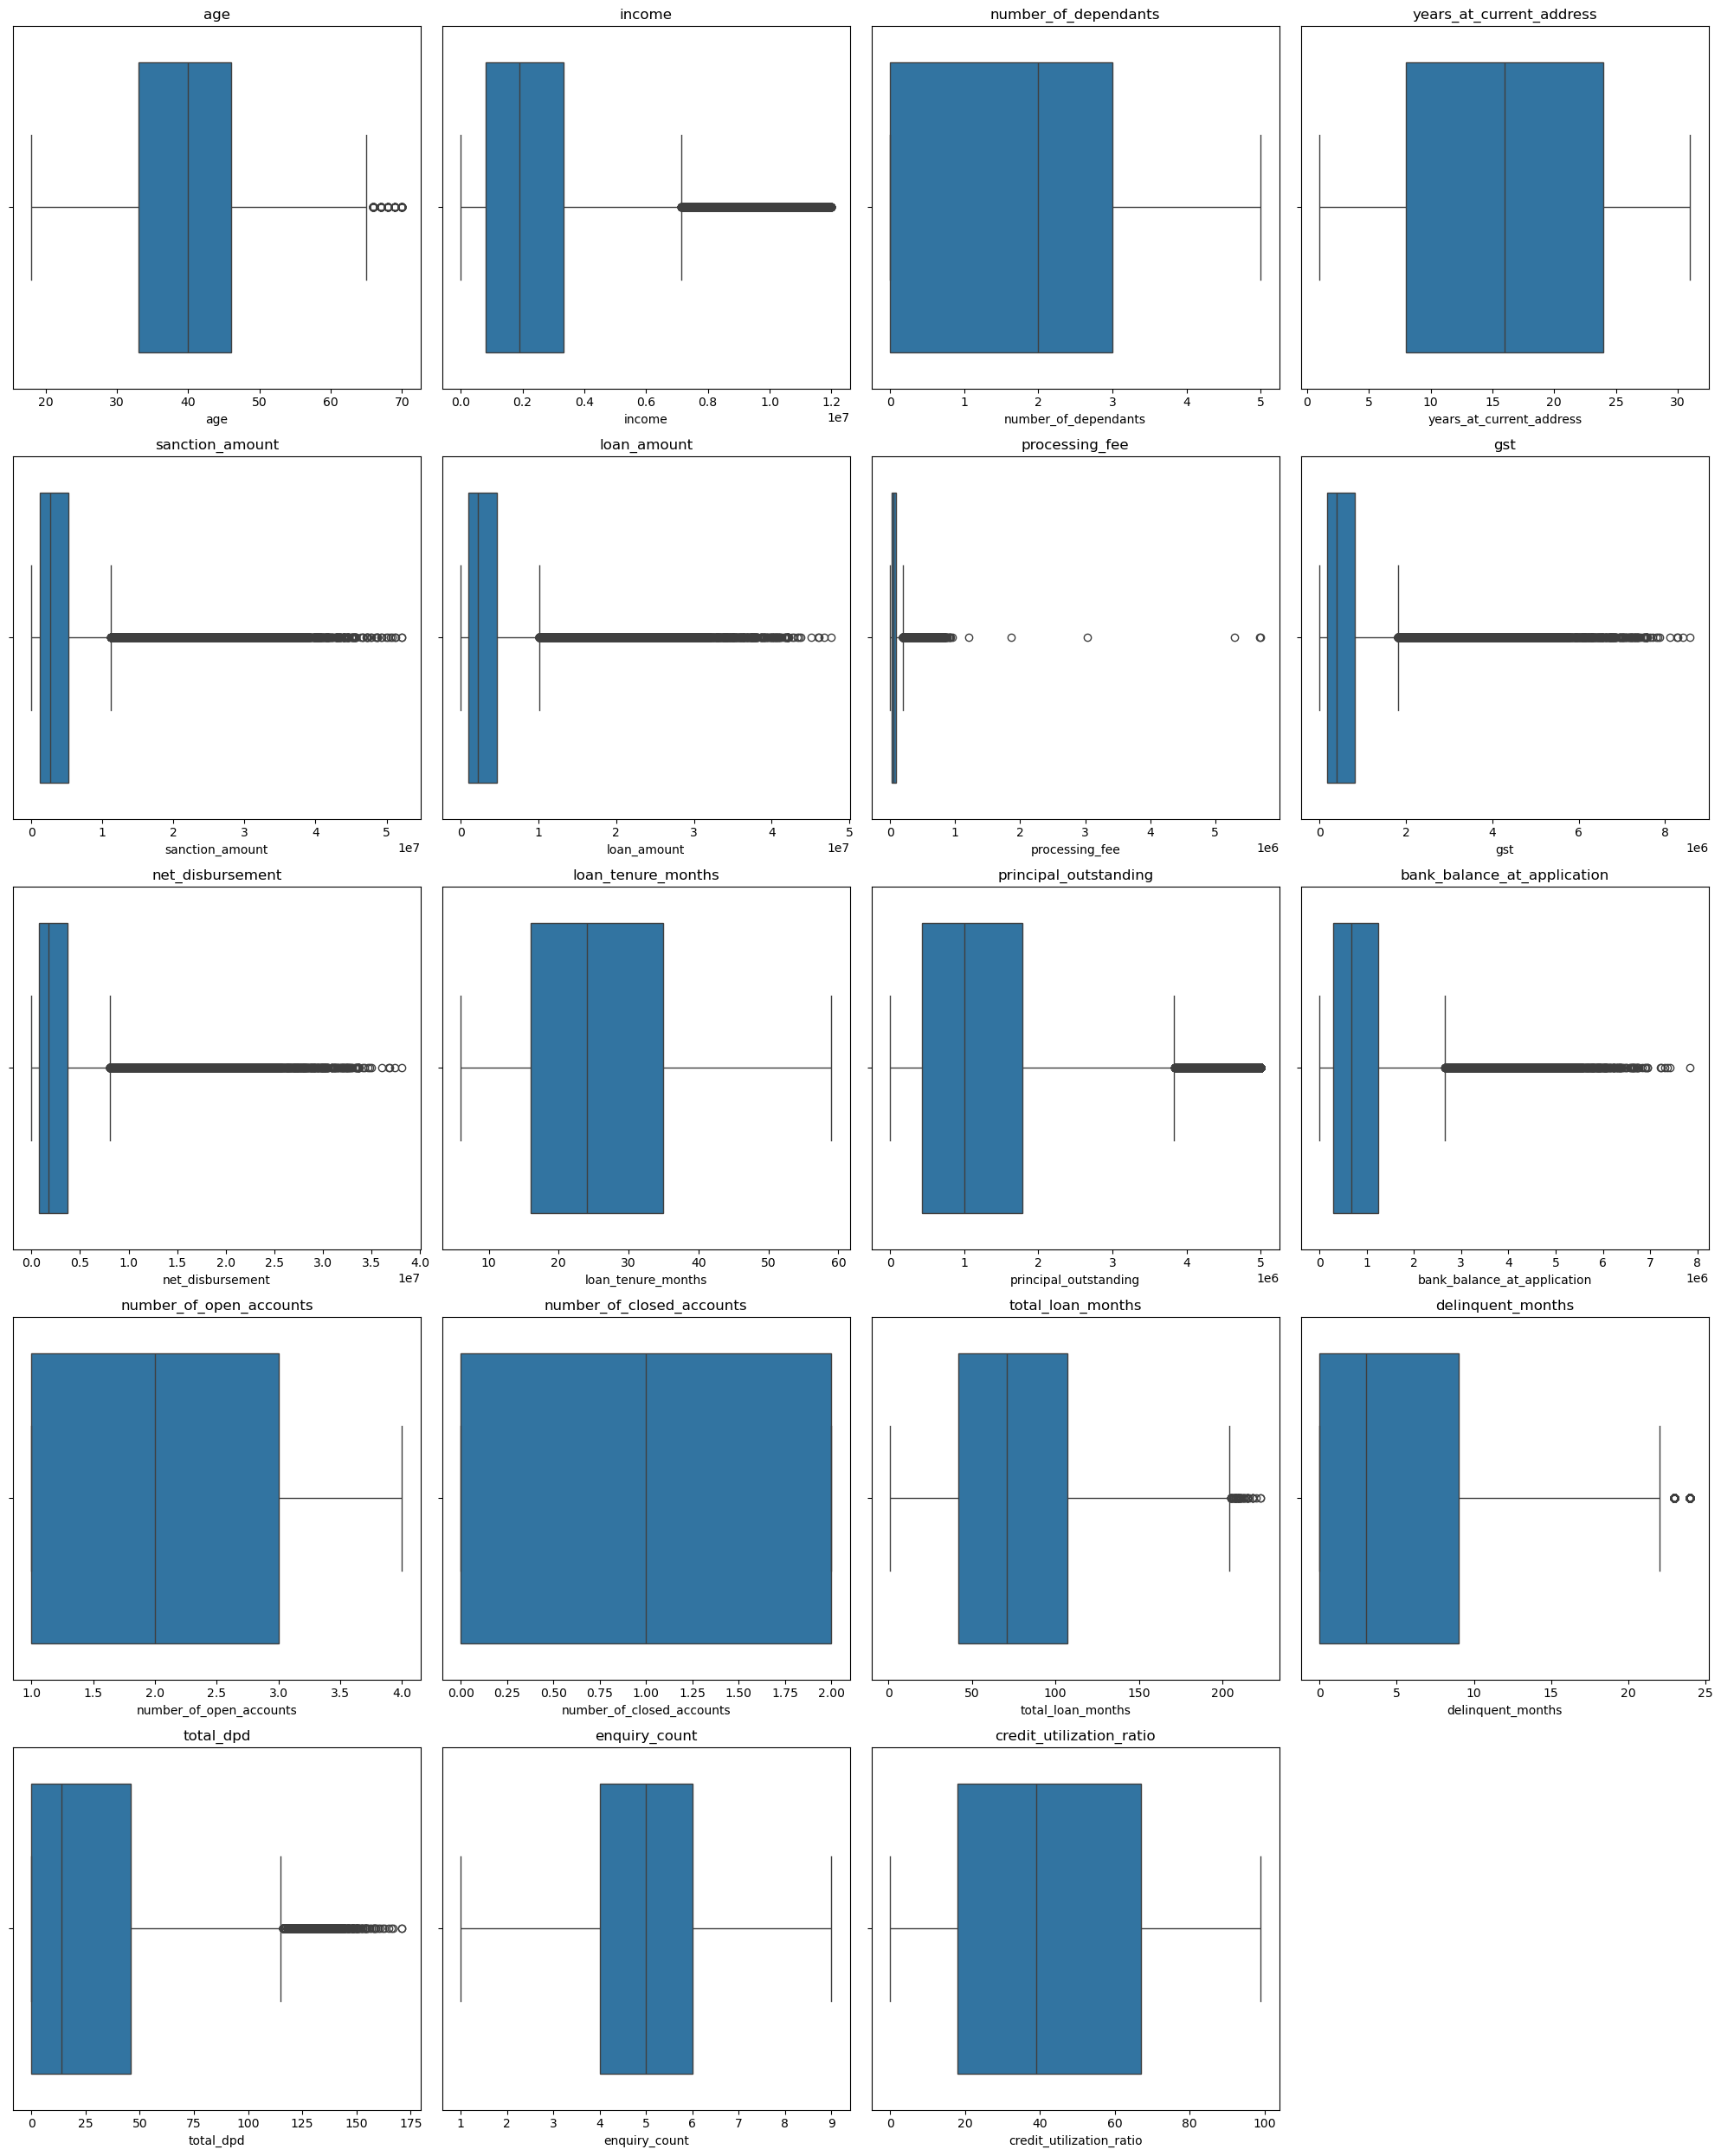

In [141]:
num_plots = len(columns_continuous)
num_cols = 4  
num_rows = (num_plots + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows))  # Adjust the figure size as needed
axes = axes.flatten()

for i, col in enumerate(columns_continuous):
    sns.boxplot(x=df_train[col], ax=axes[i])
    axes[i].set_title(col) 

for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.savefig("app/assets/boxplot.png", 
            dpi=300, 
            bbox_inches="tight")

plt.tight_layout()
plt.show()

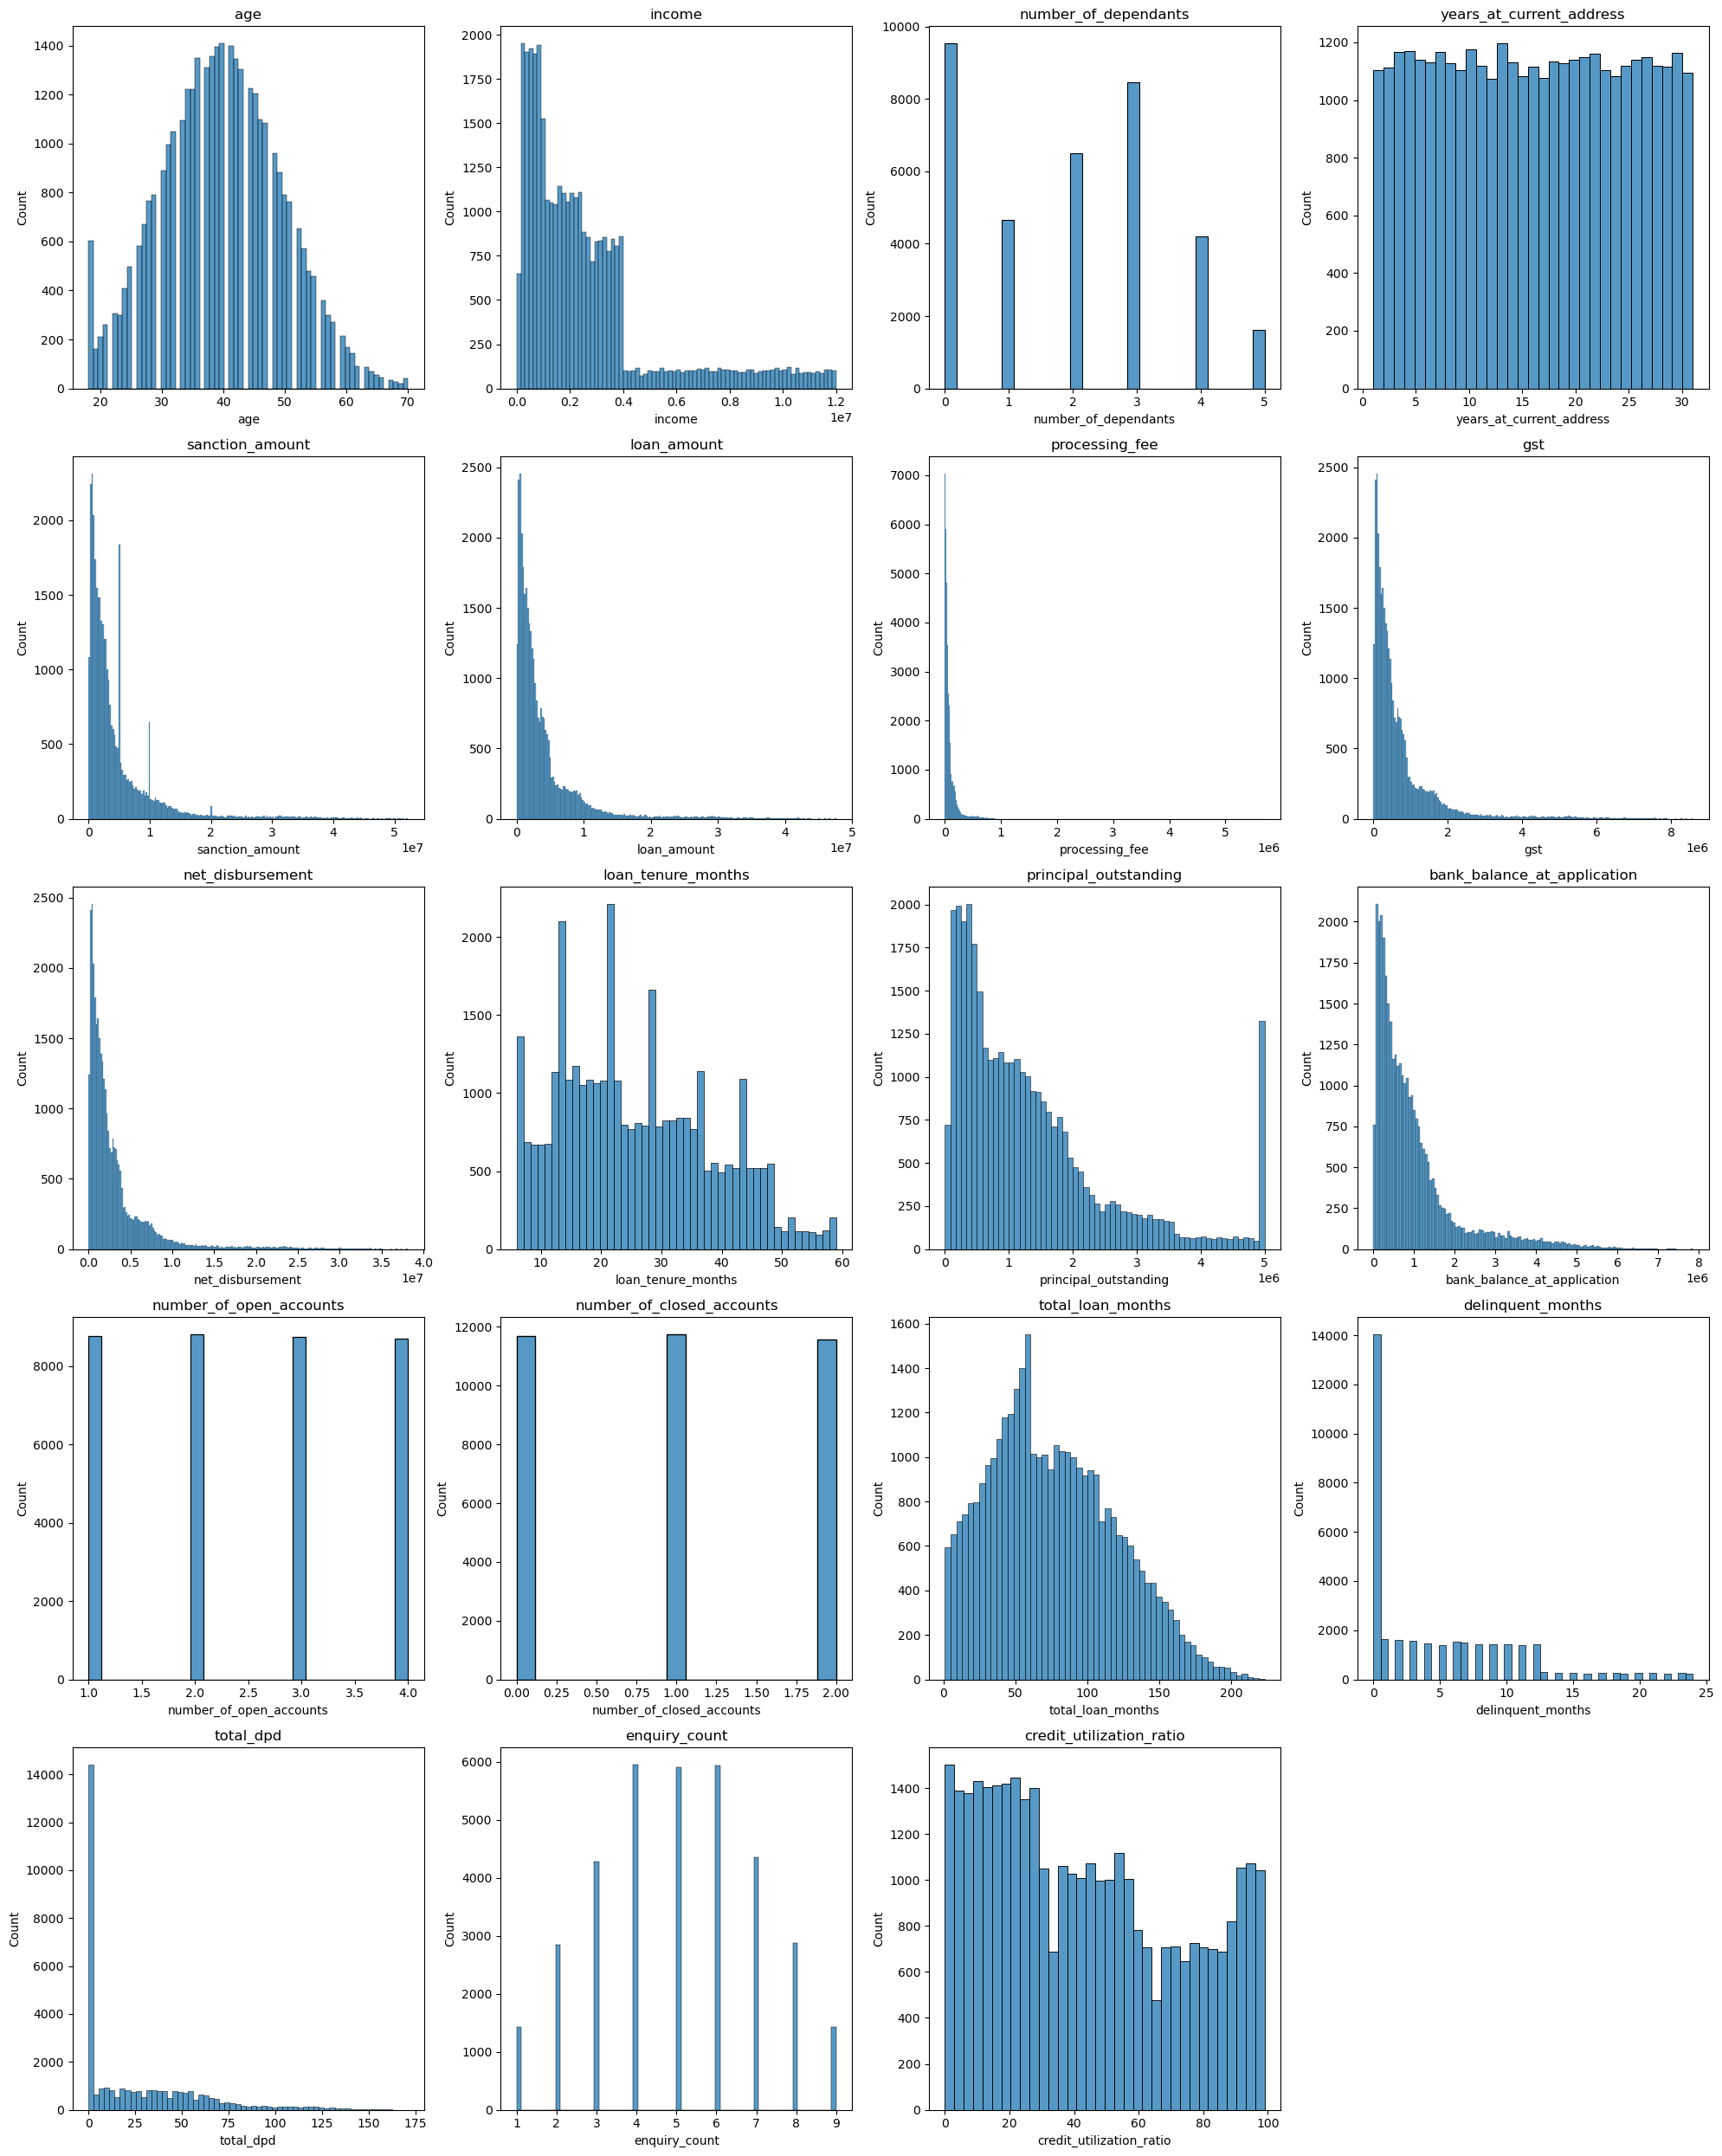

In [142]:
num_plots = len(columns_continuous)
num_cols = 4
num_rows = (num_plots + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(5 * num_cols, 5 * num_rows))
axes = axes.flatten()

for i, col in enumerate(columns_continuous):
    sns.histplot(df_train[col], ax=axes[i])
    axes[i].set_title(col) 

for j in range(i + 1, num_rows * num_cols):
    axes[j].axis('off')

plt.tight_layout()

plt.savefig("app/assets/histogram.png", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

In [143]:
pd.set_option("display.float_format", "{:.2f}".format)
df_train["processing_fee"].describe()

count     35000.00
mean      80599.42
std      120660.96
min           0.00
25%       19200.00
50%       44740.00
75%       92040.00
max     5698029.90
Name: processing_fee, dtype: float64

In [144]:
df_train["total_dpd"].describe()

count   35000.00
mean       26.92
std        32.90
min         0.00
25%         0.00
50%        14.00
75%        46.00
max       171.00
Name: total_dpd, dtype: float64

In [145]:
df_train[df_train["total_dpd"]== df["total_dpd"].max()]

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
32882,C32883,2,0,88,24,171,4,42,20,F,...,826000,16520.00,148680,660800,36,82132,120153,2022-11-05,2022-11-12,0
9540,C09541,1,1,52,24,171,1,60,43,F,...,597000,11940.00,107460,477600,18,429839,354993,2020-07-06,2020-07-08,0


In [146]:
171/24

7.125

In [147]:
df_train[df_train["processing_fee"]== df["processing_fee"].max()]

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,age,gender,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
12294,C12295,1,2,58,0,0,3,86,49,M,...,4639000,5698029.90,835020,3711200,25,1890831,1282049,2020-10-15,2020-10-23,0


In [148]:
df_train[df_train["processing_fee"]/df["loan_amount"]>0.3][["loan_amount", "processing_fee"]]

C:\Users\Sarthak\AppData\Local\Temp\ipykernel_12400\3766082229.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_train[df_train["processing_fee"]/df["loan_amount"]>0.3][["loan_amount", "processing_fee"]]


,loan_amount,processing_fee
9898,3626000,5293543.52
47089,1738000,1858964.77
33705,3812000,5678020.86
12294,4639000,5698029.90
28174,966000,1214492.67
29305,2616000,3036378.01


#### Processing fee should not be greater than 3%

In [149]:
df_train[
    df_train["processing_fee"].notna() &
    df_train["loan_amount"].notna()
][["processing_fee", "loan_amount", "gst"]].head()

,processing_fee,loan_amount,gst
38094,14140.00,707000,127260
40624,90760.00,4538000,816840
49425,120220.00,6011000,1081980
35734,6680.00,334000,60120
41708,8360.00,418000,75240


In [150]:
df_train[(df_train.processing_fee/df_train.loan_amount)>0.03][["loan_amount","processing_fee"]]

,loan_amount,processing_fee
9898,3626000,5293543.52
47089,1738000,1858964.77
33705,3812000,5678020.86
12294,4639000,5698029.90
28174,966000,1214492.67
29305,2616000,3036378.01


In [151]:
df_train_1 = df_train[df_train.processing_fee/df_train.loan_amount<0.03].copy()
df_train_1.shape

(34988, 33)

In [152]:
df_test = df_test[df_test.processing_fee/df_test.loan_amount<0.03].copy()
df_test.shape

(14997, 33)

#### Gst should be greater than 18
#### net disbursement should not be greater than loan amount

In [153]:
df_train[df_train["gst"] / df_train["loan_amount"]>0.18][["gst", "loan_amount"]]

,gst,loan_amount


In [154]:
df_train_1[df_train_1["net_disbursement"]>df_train_1["loan_amount"]][["net_disbursement", "loan_amount"]]

,net_disbursement,loan_amount


In [155]:
for col in columns_categorical:
    print(col, "-->", df_train_1[col].unique())

gender --> ['F' 'M']
marital_status --> ['Single' 'Married']
employment_status --> ['Self-Employed' 'Salaried']
residence_type --> ['Mortgage' 'Owned' 'Rented']
city --> ['Chennai' 'Ahmedabad' 'Pune' 'Kolkata' 'Mumbai' 'Hyderabad' 'Jaipur'
 'Delhi' 'Lucknow' 'Bangalore']
state --> ['Tamil Nadu' 'Gujarat' 'Maharashtra' 'West Bengal' 'Telangana'
 'Rajasthan' 'Delhi' 'Uttar Pradesh' 'Karnataka']
zipcode --> [600001 380001 411001 700001 400001 500001 302001 110001 226001 560001]
loan_purpose --> ['Home' 'Personal' 'Auto' 'Education' 'Personaal']
loan_type --> ['Secured' 'Unsecured']
default --> [0 1]


### Fixing error in loan purpose column 

In [156]:
df_train_1['loan_purpose'] = df_train_1['loan_purpose'].replace('Personaal', 'Personal')
df_train_1['loan_purpose'].unique()

array(['Home', 'Personal', 'Auto', 'Education'], dtype=object)

In [157]:
df_test['loan_purpose'] = df_test['loan_purpose'].replace('Personaal', 'Personal')
df_test['loan_purpose'].unique()

array(['Education', 'Home', 'Auto', 'Personal'], dtype=object)

<h3 style="color:blue" align="center">Exploratory Data Analysis</h3>

KDE representation of all the numerical columns 

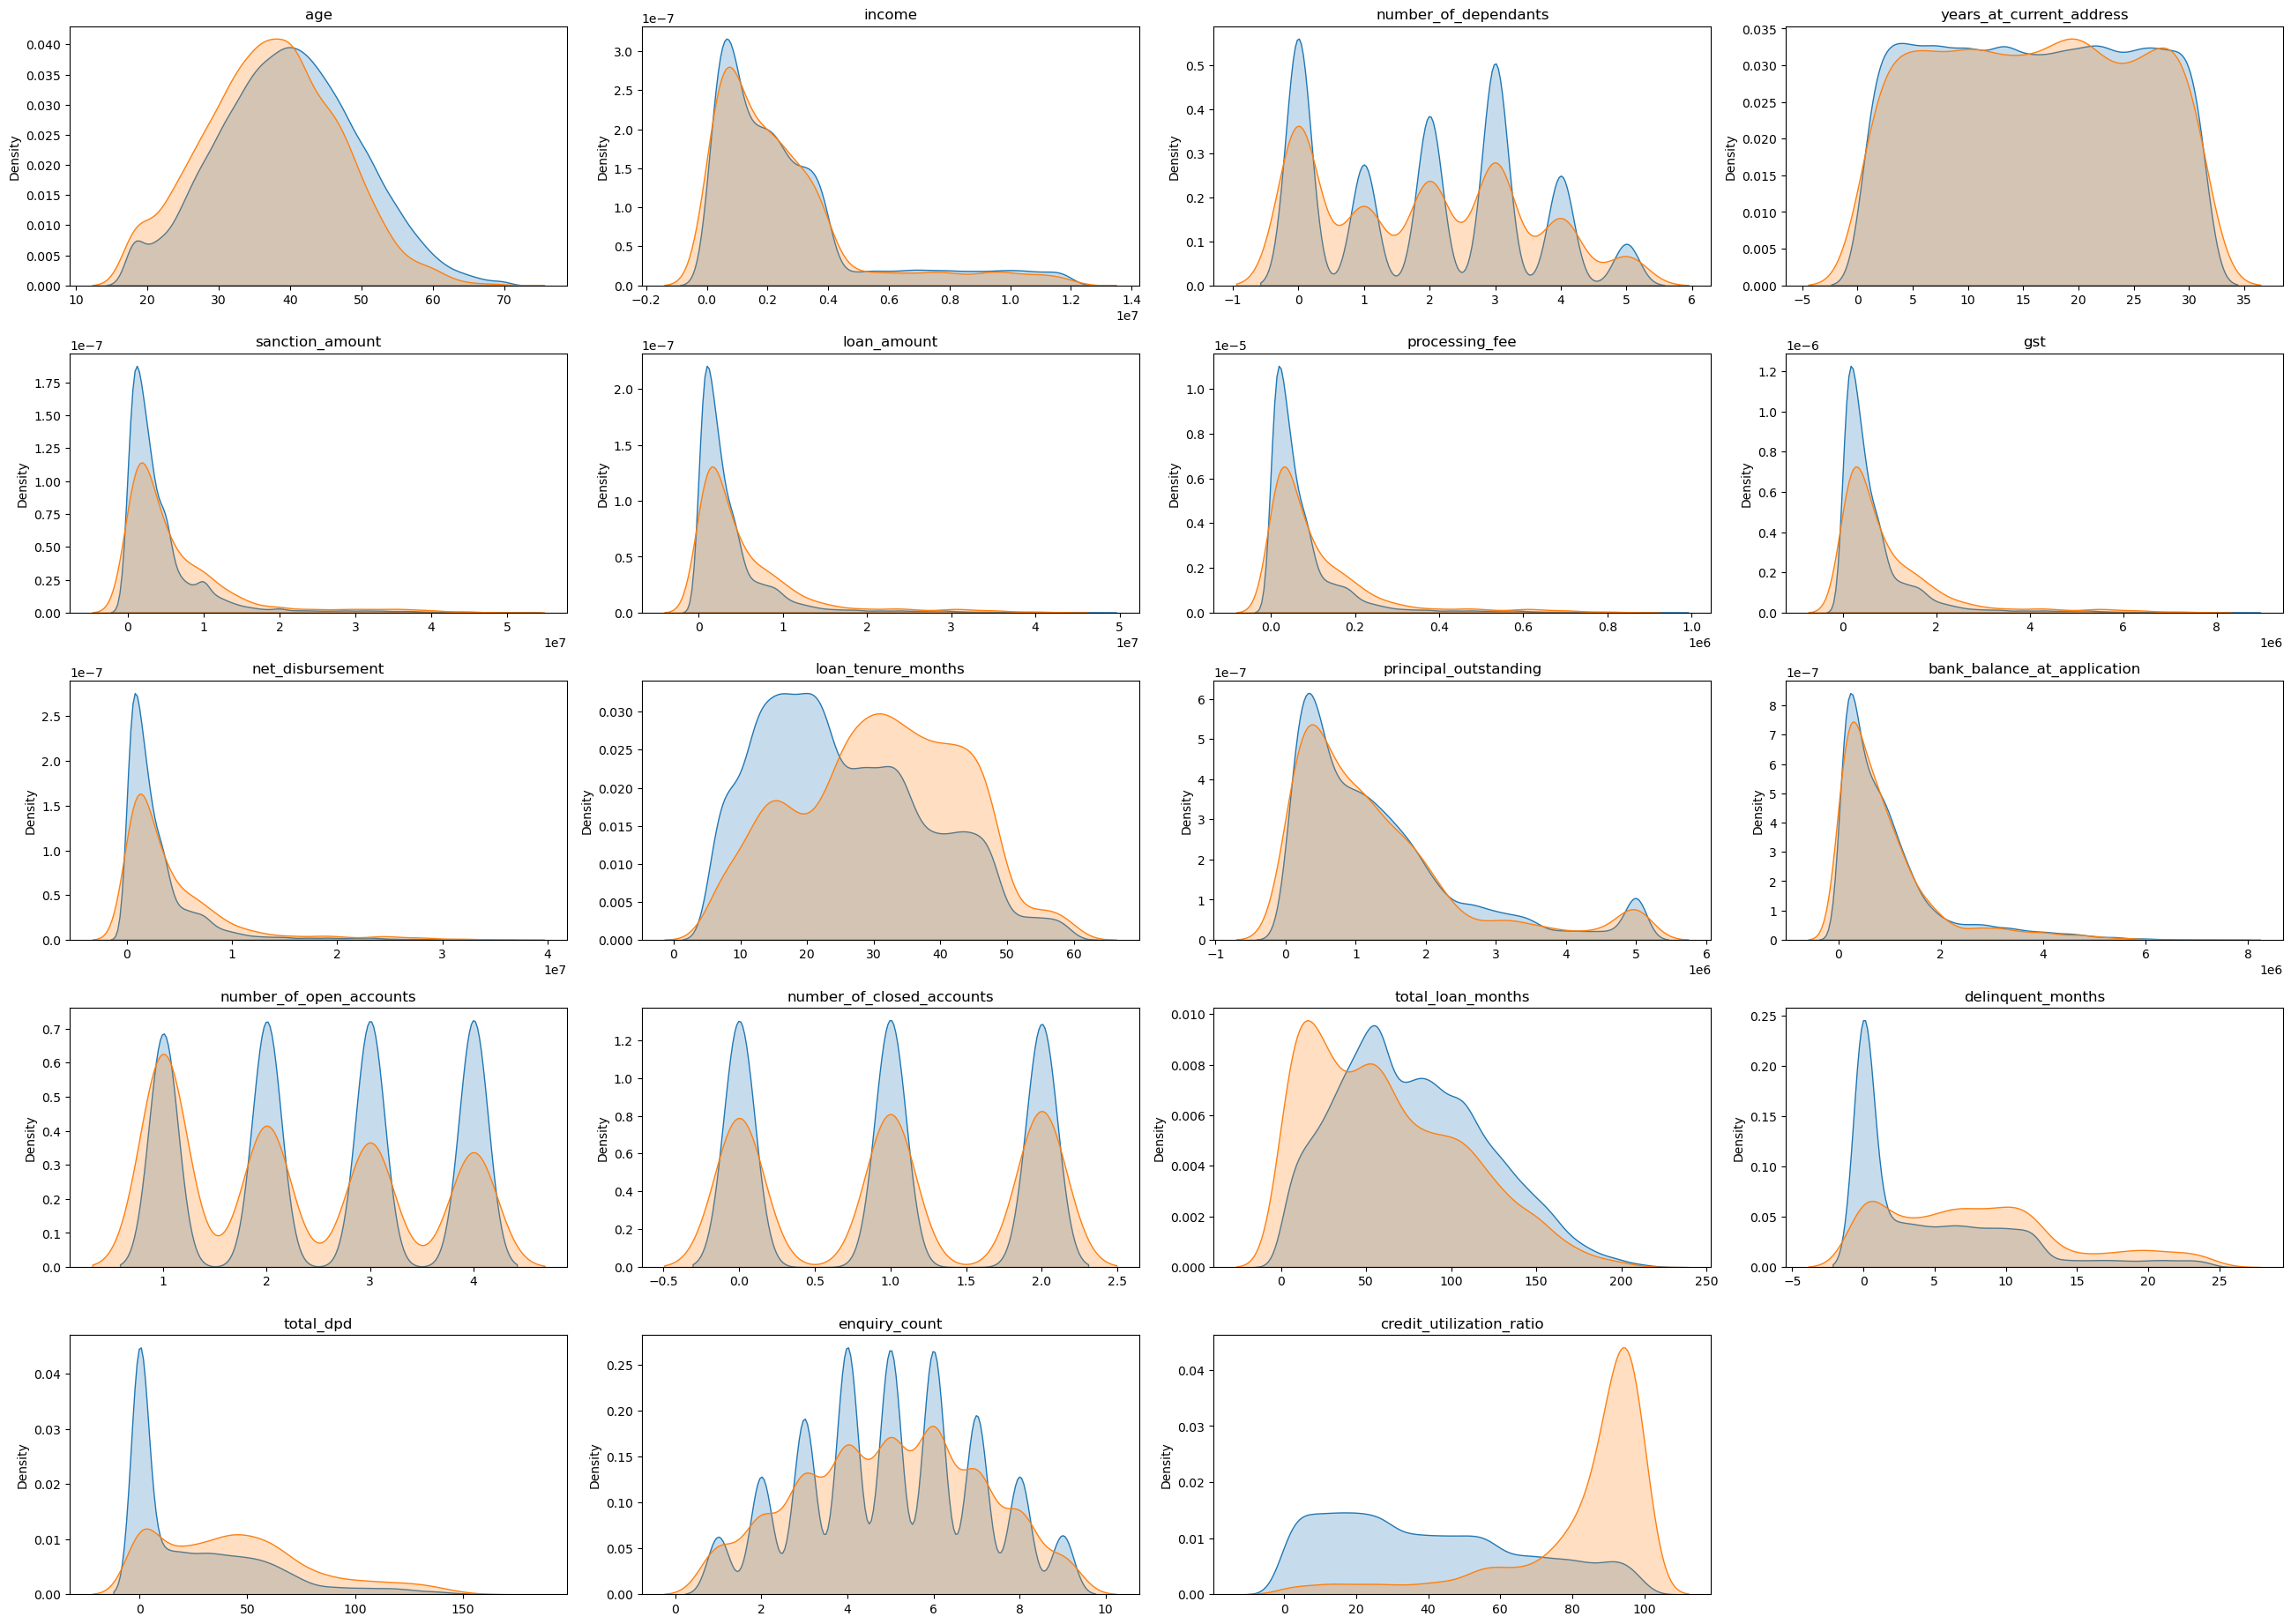

In [158]:
plt.figure(figsize=(26, 22)) 

for i, col in enumerate(columns_continuous):
    plt.subplot(6, 4, i+1)  
    sns.kdeplot(df_train_1[col][df_train_1['default']==0], fill=True, label='default=0')
    sns.kdeplot(df_train_1[col][df_train_1['default']==1], fill=True, label='default=1')
    plt.title(col)        
    plt.xlabel('')
    
plt.tight_layout()
plt.savefig("app/assets/eda_kde.png", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

#### Insights

1. In column: age, the people with younger age are likely to be default.
2. In column: loan_tenure_month, if the tenure month is more, the customer is more likely to be default
3. In column: Credit utilization ratio, the customer who utilizes all the credit limit is more likely to be 
  default.

<h3 style="color:blue" align="center">Feature Engineering, Feature Selection</h3>

#### Feature selection: Numerical Columns

#### Calculating Loan to Income ratio

In [159]:
df_train_1["loan_to_income"] = df_train_1["loan_amount"]/df_train_1["income"]
df_train_1["loan_to_income"].describe()

count   34988.00
mean        1.55
std         0.97
min         0.30
25%         0.77
50%         1.16
75%         2.45
max         4.57
Name: loan_to_income, dtype: float64

In [160]:
df_test["loan_to_income"] = df_test["loan_amount"]/df_test["income"]
df_test["loan_to_income"].describe()

count   14997.00
mean        1.56
std         0.97
min         0.30
25%         0.77
50%         1.17
75%         2.45
max         4.59
Name: loan_to_income, dtype: float64

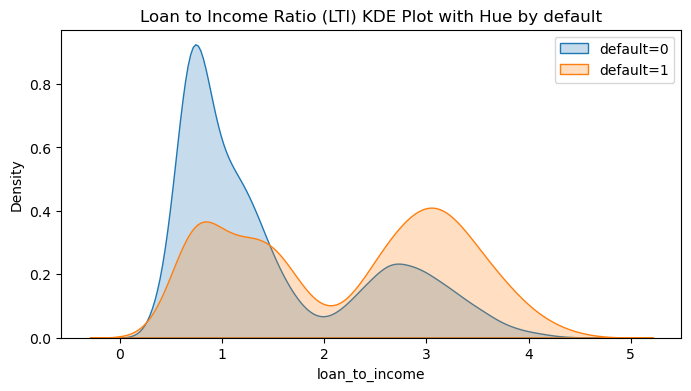

In [161]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_train_1['loan_to_income'][df_train_1['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train_1['loan_to_income'][df_train_1['default'] == 1], fill=True, label='default=1')
plt.title(f"Loan to Income Ratio (LTI) KDE Plot with Hue by default")
plt.legend()

plt.savefig("app/assets/kde_loan_to_income.png", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

Higher LTI ratio on the right side indicate that the customer with higher LTI are more likely to be default

#### Calculating delinquent ratio

In [162]:
df_train_1['delinquency_ratio'] = round((df_train_1['delinquent_months']*100 / df_train_1['total_loan_months']),2)
df_test['delinquency_ratio'] = round((df_test['delinquent_months']*100 / df_test['total_loan_months']),2)

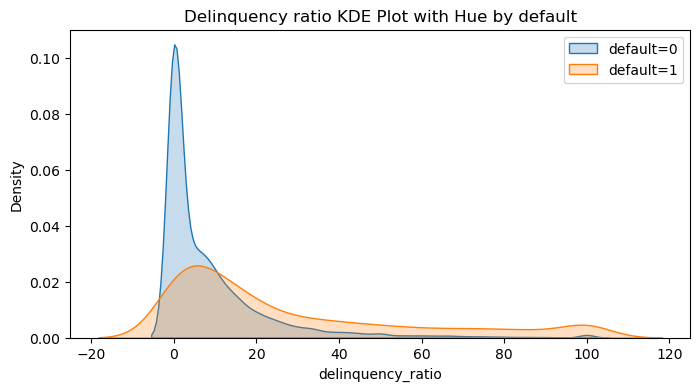

In [163]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_train_1['delinquency_ratio'][df_train_1['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train_1['delinquency_ratio'][df_train_1['default'] == 1], fill=True, label='default=1')
plt.title(f"Delinquency ratio KDE Plot with Hue by default")
plt.legend()

plt.savefig("app/assets/kde_delinquency_ratio.png", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

When the delinquency ratio are higher the customer is likely to be a default

#### Calculating avg DPD per delinquency months

In [164]:
df_train_1['avg_dpd_per_delinquency'] = np.where(
    df_train_1['delinquent_months'] != 0,
    (df_train_1['total_dpd'] / df_train_1['delinquent_months']).round(1),
    0
)

df_test['avg_dpd_per_delinquency'] = np.where(
    df_test['delinquent_months'] != 0,
    (df_test['total_dpd'] / df_test['delinquent_months']).round(1),
    0
)

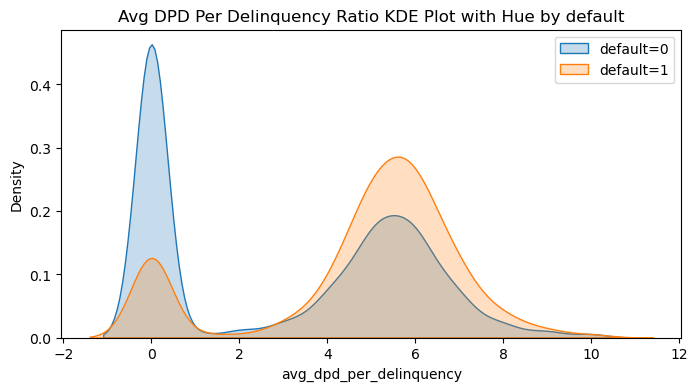

In [165]:
plt.figure(figsize=(8, 4))
sns.kdeplot(df_train_1['avg_dpd_per_delinquency'][df_train_1['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train_1['avg_dpd_per_delinquency'][df_train_1['default'] == 1], fill=True, label='default=1')
plt.title(f"Avg DPD Per Delinquency Ratio KDE Plot with Hue by default")
plt.legend()

plt.savefig("app/assets/kde_avg_dpd.png", 
            dpi=300, 
            bbox_inches="tight")

plt.show()

Graph clearly shows more occurances of default cases when avg_dpd_per_delinquency is high.

#### Removing columns that don't have influence on the target variable and model training

In [166]:
df_train_1.columns

Index(['cust_id', 'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency'],
      dtype='object')

In [167]:
df_train_2 = df_train_1.drop(['cust_id', 'loan_id','disbursal_date', 'installment_start_dt',
                              'loan_amount', 'income', 'total_loan_months',
                              'delinquent_months', 'total_dpd'],axis="columns")
df_test = df_test.drop(['cust_id', 'loan_id','disbursal_date', 'installment_start_dt',
                              'loan_amount', 'income', 'total_loan_months',
                              'delinquent_months', 'total_dpd'],axis="columns")

In [168]:
df_train_2.head(2)

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,number_of_dependants,residence_type,...,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,default,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
38094,4,0,9,42,44,F,Single,Self-Employed,0,Mortgage,...,14140.00,127260,565600,37,150837,117407,0,2.70,0.00,0.00
40624,2,2,7,8,39,M,Married,Self-Employed,4,Owned,...,90760.00,816840,3630400,21,3267359,3799236,0,0.46,0.00,0.00


In [169]:
df_train_2.columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'gender', 'marital_status',
       'employment_status', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_purpose',
       'loan_type', 'sanction_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'default', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency'],
      dtype='object')

In [170]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35000 entries, 38094 to 15795
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      35000 non-null  object 
 1   number_of_open_accounts      35000 non-null  int64  
 2   number_of_closed_accounts    35000 non-null  int64  
 3   total_loan_months            35000 non-null  int64  
 4   delinquent_months            35000 non-null  int64  
 5   total_dpd                    35000 non-null  int64  
 6   enquiry_count                35000 non-null  int64  
 7   credit_utilization_ratio     35000 non-null  int64  
 8   age                          35000 non-null  int64  
 9   gender                       35000 non-null  object 
 10  marital_status               35000 non-null  object 
 11  employment_status            35000 non-null  object 
 12  income                       35000 non-null  int64  
 13  number_of_dependa

In [171]:
df_train_2.select_dtypes("int64", "float64").columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'number_of_dependants',
       'years_at_current_address', 'zipcode', 'sanction_amount', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'default'],
      dtype='object')

#### VIF to measure multicollinearity

In [172]:
X_train = df_train_2.drop(['default', 'zipcode'], axis='columns')
y_train = df_train_2['default']

from sklearn.preprocessing import MinMaxScaler

cols_to_scale = X_train.select_dtypes(['int64', 'float64']).columns

scaler = MinMaxScaler()

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_train.describe()

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,number_of_dependants,years_at_current_address,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00,34988.00
mean,0.50,0.50,0.50,0.44,0.42,0.39,0.50,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.29,0.10,0.33
std,0.37,0.41,0.25,0.30,0.19,0.31,0.30,0.12,0.11,0.11,0.11,0.23,0.24,0.13,0.23,0.17,0.29
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.38,0.18,0.29,0.00,0.23,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.11,0.00,0.00
50%,0.33,0.50,0.50,0.39,0.42,0.40,0.50,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.20,0.04,0.43
75%,0.67,1.00,0.62,0.68,0.54,0.60,0.77,0.10,0.10,0.10,0.10,0.55,0.35,0.16,0.51,0.13,0.58
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [173]:
X_test = df_test.drop(['default', 'zipcode'], axis='columns')
y_test = df_test['default']

X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])
X_test.describe()

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,number_of_dependants,years_at_current_address,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00,14997.00
mean,0.50,0.50,0.50,0.44,0.41,0.39,0.50,0.09,0.08,0.08,0.08,0.38,0.26,0.12,0.30,0.10,0.33
std,0.37,0.41,0.25,0.30,0.19,0.31,0.30,0.12,0.11,0.11,0.11,0.23,0.25,0.13,0.23,0.17,0.29
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.38,0.18,0.29,0.00,0.27,0.02,0.02,0.02,0.02,0.19,0.08,0.03,0.11,0.00,0.00
50%,0.67,0.50,0.50,0.39,0.40,0.40,0.50,0.05,0.05,0.05,0.05,0.34,0.19,0.08,0.20,0.04,0.43
75%,1.00,1.00,0.75,0.68,0.54,0.60,0.77,0.10,0.10,0.10,0.10,0.55,0.35,0.16,0.51,0.13,0.58
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.96,1.00,1.00,1.00,1.00,1.00,0.88,1.01,1.00,1.00


In [174]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Column'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values,i) for i in range(data.shape[1])]
    return vif_df

In [175]:
calculate_vif(X_train[cols_to_scale])

C:\Users\Sarthak\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Column,VIF
0,number_of_open_accounts,4.35
1,number_of_closed_accounts,2.34
2,enquiry_count,6.33
3,credit_utilization_ratio,2.89
4,age,5.58
5,number_of_dependants,2.72
6,years_at_current_address,3.35
7,sanction_amount,102.05
8,processing_fee,inf
9,gst,inf


#### Removing the VIF values greater than 10

In [176]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement','principal_outstanding']


X_train_1 = X_train.drop(features_to_drop_vif, axis='columns')
numeric_columns = X_train_1.select_dtypes(['int64', 'float64']).columns
numeric_columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'number_of_dependants',
       'years_at_current_address', 'loan_tenure_months',
       'bank_balance_at_application', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='object')

In [177]:
vif_df = calculate_vif(X_train_1[numeric_columns])
vif_df

,Column,VIF
0,number_of_open_accounts,4.32
1,number_of_closed_accounts,2.33
2,enquiry_count,6.30
3,credit_utilization_ratio,2.87
4,age,5.29
5,number_of_dependants,2.72
6,years_at_current_address,3.33
7,loan_tenure_months,5.96
8,bank_balance_at_application,1.79
9,loan_to_income,4.52


In [178]:
len(numeric_columns)

12

In [179]:
selected_numeric_features_vif = vif_df.Column.values
selected_numeric_features_vif

array(['number_of_open_accounts', 'number_of_closed_accounts',
       'enquiry_count', 'credit_utilization_ratio', 'age',
       'number_of_dependants', 'years_at_current_address',
       'loan_tenure_months', 'bank_balance_at_application',
       'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency'],
      dtype=object)

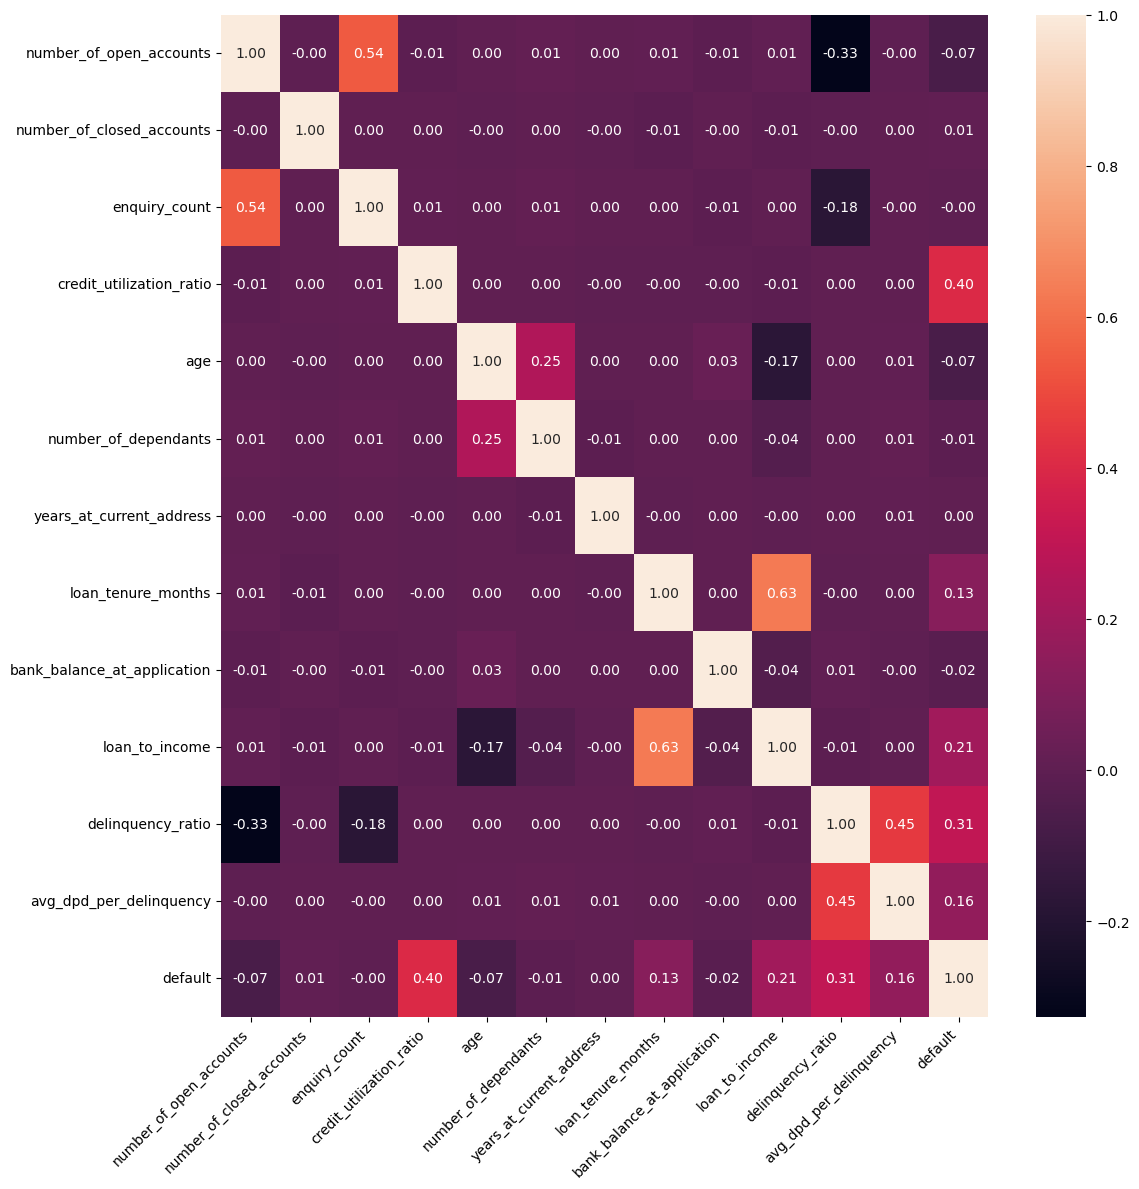

In [180]:
plt.figure(figsize=(12,12))
cm = df_train_2[numeric_columns.append(pd.Index(['default']))].corr()
sns.heatmap(cm, annot=True, fmt='0.2f')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("app/assets/correlation_heatmap.png", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

#### Feature Selection: Categorical Features

In [181]:
X_train_1.head(3)

,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,age,gender,marital_status,employment_status,number_of_dependants,residence_type,years_at_current_address,city,state,loan_purpose,loan_type,loan_tenure_months,bank_balance_at_application,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
38094,1.00,0.00,1.00,0.42,0.50,F,Single,Self-Employed,0.00,Mortgage,0.50,Chennai,Tamil Nadu,Home,Secured,0.58,0.01,0.56,0.00,0.00
40624,0.33,1.00,0.75,0.08,0.40,M,Married,Self-Employed,0.80,Owned,0.50,Ahmedabad,Gujarat,Personal,Unsecured,0.28,0.48,0.04,0.00,0.00
49425,1.00,0.50,0.75,0.27,0.37,F,Married,Self-Employed,0.80,Owned,0.97,Pune,Maharashtra,Auto,Secured,0.40,0.23,0.19,0.00,0.00


In [182]:
X_train_1.shape

(34988, 20)

In [183]:
categorical_column = X_train_1.select_dtypes(["object"]).columns
categorical_column

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type'],
      dtype='object')

In [184]:
numeric_columns

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'number_of_dependants',
       'years_at_current_address', 'loan_tenure_months',
       'bank_balance_at_application', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='object')

#### Calculating WOE and Iv

In [185]:
temp = pd.concat([X_train_1, y_train], axis=1)
temp.groupby("loan_purpose")["default"].agg(["count", "sum"])

,count,sum
loan_purpose,,
Auto,6925,299
Education,5265,519
Home,10510,1635
Personal,12288,542


In [186]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(['count','sum'])
    grouped = grouped.rename(columns={'count': 'total', 'sum': 'bad'})
    grouped['good']=grouped['total']-grouped['bad']
    
    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()
    
    grouped['bad_pct'] = grouped['bad'] / total_bad
    grouped['good_pct'] = grouped['good'] / total_good
    grouped['woe'] = np.log(grouped['good_pct']/ grouped['bad_pct'])
    grouped['iv'] = (grouped['good_pct'] -grouped['bad_pct'])*grouped['woe']
    
    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)
    
    total_iv = grouped['iv'].sum()
    
    return grouped, total_iv

grouped, total_iv = calculate_woe_iv(pd.concat([X_train_1, y_train],axis=1), 'loan_purpose', 'default')
grouped

,total,bad,good,bad_pct,good_pct,woe,iv
loan_purpose,,,,,,,
Auto,6925,299,6626,0.10,0.21,0.73,0.08
Education,5265,519,4746,0.17,0.15,-0.16,0.00
Home,10510,1635,8875,0.55,0.28,-0.68,0.18
Personal,12288,542,11746,0.18,0.37,0.71,0.13


In [187]:
iv_values = {}

for feature in X_train_1.columns:
    if X_train_1[feature].dtype == 'object':
        _, iv = calculate_woe_iv(pd.concat([X_train_1, y_train],axis=1), feature, 'default' )
    else:
        X_binned = pd.cut(X_train_1[feature], bins=10, labels=False)
        _, iv = calculate_woe_iv(pd.concat([X_binned, y_train],axis=1), feature, 'default' )
    iv_values[feature] = iv
        
iv_values

{'number_of_open_accounts': np.float64(0.07325581356695363),
 'number_of_closed_accounts': np.float64(0.0005687210026574271),
 'enquiry_count': np.float64(0.005456328413885872),
 'credit_utilization_ratio': np.float64(2.3927055862612425),
 'age': np.float64(0.07694701309826596),
 'gender': np.float64(0.0005709662521100581),
 'marital_status': np.float64(0.0023191641073453083),
 'employment_status': np.float64(0.0024389987478871805),
 'number_of_dependants': np.float64(0.004617166112341162),
 'residence_type': np.float64(0.25864377110359527),
 'years_at_current_address': np.float64(0.0008423568825644971),
 'city': np.float64(0.0009145141559576687),
 'state': np.float64(0.0008165745047632679),
 'loan_purpose': np.float64(0.39563682588883553),
 'loan_type': np.float64(0.17971560979330453),
 'loan_tenure_months': np.float64(0.23560718802185557),
 'bank_balance_at_application': np.float64(0.005901492342451912),
 'loan_to_income': np.float64(0.4955604837668265),
 'delinquency_ratio': np.floa

In [188]:
pd.set_option('display.float_format', lambda x: '{:.3f}'.format(x))

iv_df = pd.DataFrame(list(iv_values.items()), columns=['Feature', 'IV'])
iv_df = iv_df.sort_values(by='IV', ascending=False)
iv_df

,Feature,IV
3,credit_utilization_ratio,2.393
18,delinquency_ratio,0.683
17,loan_to_income,0.496
19,avg_dpd_per_delinquency,0.423
13,loan_purpose,0.396
9,residence_type,0.259
15,loan_tenure_months,0.236
14,loan_type,0.180
4,age,0.077
0,number_of_open_accounts,0.073


In [189]:
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['number_of_open_accounts',
 'credit_utilization_ratio',
 'age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency']

#### Feature Encoding

In [190]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test[selected_features_iv]

In [191]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_train_encoded.head(3)

,number_of_open_accounts,credit_utilization_ratio,age,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
38094,1.000,0.424,0.500,0.585,0.563,0.000,0.000,False,False,False,True,False,False
40624,0.333,0.081,0.404,0.283,0.039,0.000,0.000,True,False,False,False,True,True
49425,1.000,0.273,0.365,0.396,0.192,0.000,0.000,True,False,False,False,False,False


In [192]:
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)
X_test_encoded.head(3)

,number_of_open_accounts,credit_utilization_ratio,age,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
33553,0.333,0.121,0.346,0.528,0.258,0.043,0.900,True,False,True,False,False,False
9427,1.000,0.859,0.288,0.623,0.690,0.000,0.000,True,False,False,True,False,False
199,1.000,0.727,0.192,0.623,0.637,0.000,0.000,True,False,False,True,False,False


<h3 align="center" style="color:blue">Model Training</h3>

#### Attempt 1:
 Using Logistic Regression, XGBoost, RandomForest

In [193]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13695
           1       0.83      0.70      0.76      1302

    accuracy                           0.96     14997
   macro avg       0.90      0.84      0.87     14997
weighted avg       0.96      0.96      0.96     14997



In [194]:
print(model.coef_[0] ,  model.intercept_)

[ 0.62052211 12.47150009 -0.52712311  0.49203637 10.46431708  9.28302094
  2.02577385 -1.4750266   1.52021835  0.99179738 -1.23891298  0.64967051
  0.64967051] [-17.26542026]


In [195]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     13695
           1       0.85      0.71      0.77      1302

    accuracy                           0.96     14997
   macro avg       0.91      0.85      0.88     14997
weighted avg       0.96      0.96      0.96     14997



In [196]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(X_train_encoded, y_train)

y_pred = model.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     13695
           1       0.81      0.74      0.77      1302

    accuracy                           0.96     14997
   macro avg       0.89      0.86      0.87     14997
weighted avg       0.96      0.96      0.96     14997



#### Attempt 2:
1. Handling class imbalance using SMOTE Tomek
2. Using randomized searchcv for logistic regression and xgboost to try different parameter

In [197]:
from imblearn.combine import SMOTETomek

smt = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)
y_train_smt.value_counts()

default
0    31928
1    31928
Name: count, dtype: int64

In [198]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'C': np.logspace(-4, 4, 20),  # Logarithmically spaced values from 10^-4 to 10^4
    'solver': ['lbfgs', 'saga', 'liblinear', 'newton-cg']   # Algorithm to use in the optimization problem
}

# Create the Logistic Regression model
log_reg = LogisticRegression(max_iter=10000)  # Increased max_iter for convergence

# Set up RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=param_dist,
    n_iter=50,  # Number of parameter settings that are sampled
    scoring='f1',
    cv=3,  # 5-fold cross-validation
    verbose=2,
    random_state=42,  # Set a random state for reproducibility
    n_jobs=-1  # Use all available cores
)

# Fit the RandomizedSearchCV to the training data
random_search.fit(X_train_smt, y_train_smt)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameters: {'solver': 'liblinear', 'C': np.float64(1.623776739188721)}
Best Score: 0.9456944263353622
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     13695
           1       0.56      0.94      0.70      1302

    accuracy                           0.93     14997
   macro avg       0.78      0.94      0.83     14997
weighted avg       0.96      0.93      0.94     14997



In [199]:
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'scale_pos_weight': [1, 2, 3, 5, 7, 10],
    'reg_alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0] ,
    'reg_lambda': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]  
}

xgb = XGBClassifier()

random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_dist, n_iter=100,
                                   scoring='f1', cv=3, verbose=1, n_jobs=-1, random_state=42)

random_search.fit(X_train_smt, y_train_smt)

# Print the best parameters and best score
print(f"Best Parameters: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test_encoded)
print("Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'subsample': 1.0, 'scale_pos_weight': 1, 'reg_lambda': 0.1, 'reg_alpha': 0.1, 'n_estimators': 250, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
Best Score: 0.978462956217069
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     13695
           1       0.74      0.83      0.78      1302

    accuracy                           0.96     14997
   macro avg       0.86      0.90      0.88     14997
weighted avg       0.96      0.96      0.96     14997



#### Solving Credit risk probelm, so the recall is more importance as we don't want to miss a customer which is default so the logistic regression model perform better than xgboost classifier and also Logistic regression will be a better model to explain to stakeholder in terms of technical knowledge.

#### Attempt 3:
1. Handled class imbalance using Smote Tonek
2. using logistic regression
3. using cross validation
4. Parameter tuning using optuna
5. Using early stopping for computational resources

In [200]:
import optuna
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_val_score

In [201]:
class EarlyStoppingCallback:
    def __init__(self, patience=5):
        self.patience = patience

    def __call__(self, study, trial):
        if trial.number - study.best_trial.number >= self.patience:
            print(f"Early stopping at trial {trial.number}: no improvement for "
                  f"{self.patience} trials after best trial {study.best_trial.number}.")
            study.stop()

f1_scorer = make_scorer(f1_score, average='macro')

def objective(trial):
    param = {
        'C': trial.suggest_float('C', 1e-4, 1e4, log=True),
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear', 'saga', 'newton-cg']),
        'tol': trial.suggest_float('tol', 1e-6, 1e-1, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
    }
    model = LogisticRegression(**param, max_iter=10000)
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3,
                             scoring=f1_scorer, n_jobs=-1)
    return np.mean(scores)

study_logistic = optuna.create_study(direction='maximize')
study_logistic.optimize(
    objective,
    n_trials=50,                                   
    callbacks=[EarlyStoppingCallback(patience=5)]  
)

# Best result
best_trial = study_logistic.best_trial
print('Best trial:', best_trial.number)
print('  Best CV macro F1:', best_trial.value)
print('  Best params:')
for key, value in best_trial.params.items():
    print(f'    {key}: {value}')


best_model_logistic = LogisticRegression(**study_logistic.best_params, max_iter=10000)
best_model_logistic.fit(X_train_smt, y_train_smt)

y_pred = best_model_logistic.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

[I 2026-10-07 23:30:36,196] A new study created in memory with name: no-name-f4bc47c8-30bc-4f46-8e74-e591c6d59341
[I 2026-10-07 23:30:36,835] Trial 0 finished with value: 0.8226549903517789 and parameters: {'C': 0.00011421255731044235, 'solver': 'saga', 'tol': 5.652091139336291e-06, 'class_weight': None}. Best is trial 0 with value: 0.8226549903517789.
[I 2026-10-07 23:30:37,407] Trial 1 finished with value: 0.9444090258822814 and parameters: {'C': 10.678922069517839, 'solver': 'saga', 'tol': 3.0175065504656853e-06, 'class_weight': None}. Best is trial 1 with value: 0.9444090258822814.
[I 2026-10-07 23:30:37,708] Trial 2 finished with value: 0.9446099177629131 and parameters: {'C': 1.7618354573867834, 'solver': 'newton-cg', 'tol': 0.00045472254228923626, 'class_weight': 'balanced'}. Best is trial 2 with value: 0.9446099177629131.
[I 2026-10-07 23:30:38,000] Trial 3 finished with value: 0.9446221171900655 and parameters: {'C': 2.6228825313090636, 'solver': 'liblinear', 'tol': 0.01890165

Early stopping at trial 12: no improvement for 5 trials after best trial 7.
Best trial: 7
  Best CV macro F1: 0.9447828850188263
  Best params:
    C: 3.39617781488631
    solver: liblinear
    tol: 0.0003365913170340555
    class_weight: balanced
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     13695
           1       0.56      0.94      0.70      1302

    accuracy                           0.93     14997
   macro avg       0.78      0.93      0.83     14997
weighted avg       0.96      0.93      0.94     14997



#### Attempt 4:
1. Handled class imbalance using Smote Tonek
2. using XGBoost
3. using cross validation
4. Parameter tuning using optuna
5. Using early stopping for computational resources

In [202]:
class EarlyStoppingCallback:
    def __init__(self, patience=3):
        self.patience = patience

    def __call__(self, study, trial):
        if trial.number - study.best_trial.number >= self.patience:
            print(f"Early stopping at trial {trial.number}: no improvement for "
                  f"{self.patience} trials after best trial {study.best_trial.number}.")
            study.stop()

f1_scorer = make_scorer(f1_score, average='macro')

def objective(trial):
    param = {
         'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'verbosity': 0,
        'booster': 'gbtree',
        'lambda': trial.suggest_float('lambda', 1e-3, 10.0, log=True),
        'alpha': trial.suggest_float('alpha', 1e-3, 10.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.4, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'eta': trial.suggest_float('eta', 0.01, 0.3),
        'gamma': trial.suggest_float('gamma', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 10)
    }
    model = XGBClassifier(**param, max_iter=10000)
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3,
                             scoring=f1_scorer, n_jobs=-1)
    return np.mean(scores)

study_xgb = optuna.create_study(direction='maximize')
study_xgb.optimize(
    objective,
    n_trials=50,                                   
    callbacks=[EarlyStoppingCallback(patience=5)]  
)

# Best result
best_trial = study_xgb.best_trial
print('Best trial:', best_trial.number)
print('  Best CV macro F1:', best_trial.value)
print('  Best params:')
for key, value in best_trial.params.items():
    print(f'    {key}: {value}')


best_model_XGB = XGBClassifier(**study_xgb.best_params, max_iter=10000)
best_model_XGB.fit(X_train_smt, y_train_smt)

# Test set evaluation
y_pred = best_model_XGB.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

[I 2026-10-07 23:30:40,919] A new study created in memory with name: no-name-ac7847ac-4045-4718-8921-a34a0b55bb2e
[I 2026-10-07 23:30:41,806] Trial 0 finished with value: 0.9284365677790517 and parameters: {'lambda': 0.2524202176818886, 'alpha': 2.5142828656356344, 'subsample': 0.9010674157213099, 'colsample_bytree': 0.8669851917124753, 'max_depth': 3, 'eta': 0.10050889979750818, 'gamma': 9.182607876828436, 'scale_pos_weight': 8.363891733791098, 'min_child_weight': 9, 'max_delta_step': 6}. Best is trial 0 with value: 0.9284365677790517.
[I 2026-10-07 23:30:42,991] Trial 1 finished with value: 0.9639114365983646 and parameters: {'lambda': 4.389221964084357, 'alpha': 0.04100321797504518, 'subsample': 0.6847169254609907, 'colsample_bytree': 0.5803791070312693, 'max_depth': 7, 'eta': 0.14383173574189678, 'gamma': 4.654165601666906, 'scale_pos_weight': 4.307523297096838, 'min_child_weight': 2, 'max_delta_step': 2}. Best is trial 1 with value: 0.9639114365983646.
[I 2026-10-07 23:30:44,171] 

Early stopping at trial 17: no improvement for 5 trials after best trial 12.
Best trial: 12
  Best CV macro F1: 0.9745138935081755
  Best params:
    lambda: 2.6124915372028825
    alpha: 0.23539260572648824
    subsample: 0.49918428557853006
    colsample_bytree: 0.8526132443544189
    max_depth: 10
    eta: 0.25382908652431946
    gamma: 0.9074519815826829
    scale_pos_weight: 2.0524888255765905
    min_child_weight: 10
    max_delta_step: 1
              precision    recall  f1-score   support

           0       0.99      0.97      0.98     13695
           1       0.71      0.86      0.78      1302

    accuracy                           0.96     14997
   macro avg       0.85      0.92      0.88     14997
weighted avg       0.96      0.96      0.96     14997



#### As recall is over main priority so we will be chosing the logistic regression model of attempt 3

## Model Evaluation : ROC/AUC

In [203]:
y_pred = best_model_logistic.predict(X_test_encoded)
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     13695
           1       0.56      0.94      0.70      1302

    accuracy                           0.93     14997
   macro avg       0.78      0.93      0.83     14997
weighted avg       0.96      0.93      0.94     14997



In [204]:
from sklearn.metrics import roc_curve

probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, probabilities)

fpr[:5], tpr[:5], thresholds[:5]

(array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 7.30193501e-05,
        7.30193501e-05]),
 array([0.        , 0.00076805, 0.16973886, 0.16973886, 0.21505376]),
 array([       inf, 0.99999992, 0.99921102, 0.99920398, 0.99857089]))

In [205]:
from sklearn.metrics import auc

area = auc(fpr, tpr)
area

0.9831606835104699

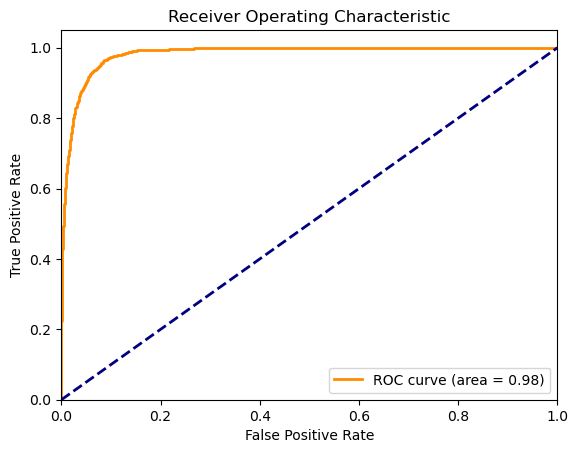

In [206]:
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % area)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")

plt.savefig("app/assets/roc_curve.png", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

### Model Evaluation : Rankordering, KS statistic, Gini coeff

In [207]:
probabilities = best_model_logistic.predict_proba(X_test_encoded)[:,1]

df_eval = pd.DataFrame({
    'Default Truth': y_test,
    'Default Probability': probabilities
})
df_eval.sample(10)

,Default Truth,Default Probability
14350,0,0.035
37100,0,0.000
10648,0,0.022
38544,1,0.995
5893,0,0.000
48691,0,0.002
42905,0,0.001
40921,0,0.000
14520,0,0.000
45349,0,0.000


In [208]:
df_eval['Decile'] = pd.qcut(df_eval['Default Probability'], 10, labels=False, duplicates='drop')
df_eval.head(5)

,Default Truth,Default Probability,Decile
33553,0,0.000,1
9427,0,0.756,8
199,0,0.140,7
12447,0,0.433,8
39489,0,0.001,4


In [209]:
df_decile = df_eval.groupby('Decile').apply(lambda x: pd.Series({
    'Minimum Probability': x['Default Probability'].min(),
    'Maximum Probability': x['Default Probability'].max(),
    'Events': x['Default Truth'].sum(),
    'Non-events': x['Default Truth'].count() - x['Default Truth'].sum(),    
}))
df_decile.reset_index(inplace=True)
df_decile

C:\Users\Sarthak\AppData\Local\Temp\ipykernel_12400\4037021561.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_decile = df_eval.groupby('Decile').apply(lambda x: pd.Series({


,Decile,Minimum Probability,Maximum Probability,Events,Non-events
0,0,0.000,0.000,0.000,1500.000
1,1,0.000,0.000,0.000,1500.000
2,2,0.000,0.000,0.000,1499.000
3,3,0.000,0.000,0.000,1500.000
4,4,0.000,0.001,0.000,1500.000
5,5,0.001,0.005,1.000,1498.000
6,6,0.005,0.033,2.000,1498.000
7,7,0.033,0.210,21.000,1478.000
8,8,0.211,0.812,196.000,1304.000
9,9,0.812,1.000,1082.000,418.000


In [210]:
df_decile['Event Rate'] = df_decile['Events']*100 / (df_decile['Events']+df_decile['Non-events'])
df_decile['Non-event Rate'] = df_decile['Non-events']*100 / (df_decile['Events']+df_decile['Non-events'])
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,0,0.000,0.000,0.000,1500.000,0.000,100.000
1,1,0.000,0.000,0.000,1500.000,0.000,100.000
2,2,0.000,0.000,0.000,1499.000,0.000,100.000
3,3,0.000,0.000,0.000,1500.000,0.000,100.000
4,4,0.000,0.001,0.000,1500.000,0.000,100.000
5,5,0.001,0.005,1.000,1498.000,0.067,99.933
6,6,0.005,0.033,2.000,1498.000,0.133,99.867
7,7,0.033,0.210,21.000,1478.000,1.401,98.599
8,8,0.211,0.812,196.000,1304.000,13.067,86.933
9,9,0.812,1.000,1082.000,418.000,72.133,27.867


In [211]:
df_decile = df_decile.sort_values(by='Decile', ascending=False).reset_index(drop=True)
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,9,0.812,1.000,1082.000,418.000,72.133,27.867
1,8,0.211,0.812,196.000,1304.000,13.067,86.933
2,7,0.033,0.210,21.000,1478.000,1.401,98.599
3,6,0.005,0.033,2.000,1498.000,0.133,99.867
4,5,0.001,0.005,1.000,1498.000,0.067,99.933
5,4,0.000,0.001,0.000,1500.000,0.000,100.000
6,3,0.000,0.000,0.000,1500.000,0.000,100.000
7,2,0.000,0.000,0.000,1499.000,0.000,100.000
8,1,0.000,0.000,0.000,1500.000,0.000,100.000
9,0,0.000,0.000,0.000,1500.000,0.000,100.000


In [212]:
df_decile['Cum Events'] =  df_decile['Events'].cumsum()
df_decile['Cum Non-events'] =  df_decile['Non-events'].cumsum()
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events
0,9,0.812,1.000,1082.000,418.000,72.133,27.867,1082.000,418.000
1,8,0.211,0.812,196.000,1304.000,13.067,86.933,1278.000,1722.000
2,7,0.033,0.210,21.000,1478.000,1.401,98.599,1299.000,3200.000
3,6,0.005,0.033,2.000,1498.000,0.133,99.867,1301.000,4698.000
4,5,0.001,0.005,1.000,1498.000,0.067,99.933,1302.000,6196.000
5,4,0.000,0.001,0.000,1500.000,0.000,100.000,1302.000,7696.000
6,3,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,9196.000
7,2,0.000,0.000,0.000,1499.000,0.000,100.000,1302.000,10695.000
8,1,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,12195.000
9,0,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,13695.000


In [213]:
df_decile['Cum Event Rate'] = df_decile['Cum Events'] * 100 / df_decile['Events'].sum()
df_decile['Cum Non-event Rate'] = df_decile['Cum Non-events']*100 / df_decile['Non-events'].sum()
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate
0,9,0.812,1.000,1082.000,418.000,72.133,27.867,1082.000,418.000,83.103,3.052
1,8,0.211,0.812,196.000,1304.000,13.067,86.933,1278.000,1722.000,98.157,12.574
2,7,0.033,0.210,21.000,1478.000,1.401,98.599,1299.000,3200.000,99.770,23.366
3,6,0.005,0.033,2.000,1498.000,0.133,99.867,1301.000,4698.000,99.923,34.304
4,5,0.001,0.005,1.000,1498.000,0.067,99.933,1302.000,6196.000,100.000,45.243
5,4,0.000,0.001,0.000,1500.000,0.000,100.000,1302.000,7696.000,100.000,56.196
6,3,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,9196.000,100.000,67.149
7,2,0.000,0.000,0.000,1499.000,0.000,100.000,1302.000,10695.000,100.000,78.094
8,1,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,12195.000,100.000,89.047
9,0,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,13695.000,100.000,100.000


In [214]:
df_decile['KS'] = abs(df_decile['Cum Event Rate'] - df_decile['Cum Non-event Rate'])
df_decile

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate,KS
0,9,0.812,1.000,1082.000,418.000,72.133,27.867,1082.000,418.000,83.103,3.052,80.051
1,8,0.211,0.812,196.000,1304.000,13.067,86.933,1278.000,1722.000,98.157,12.574,85.583
2,7,0.033,0.210,21.000,1478.000,1.401,98.599,1299.000,3200.000,99.770,23.366,76.403
3,6,0.005,0.033,2.000,1498.000,0.133,99.867,1301.000,4698.000,99.923,34.304,65.619
4,5,0.001,0.005,1.000,1498.000,0.067,99.933,1302.000,6196.000,100.000,45.243,54.757
5,4,0.000,0.001,0.000,1500.000,0.000,100.000,1302.000,7696.000,100.000,56.196,43.804
6,3,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,9196.000,100.000,67.149,32.851
7,2,0.000,0.000,0.000,1499.000,0.000,100.000,1302.000,10695.000,100.000,78.094,21.906
8,1,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,12195.000,100.000,89.047,10.953
9,0,0.000,0.000,0.000,1500.000,0.000,100.000,1302.000,13695.000,100.000,100.000,0.000


### 
1. KS statistic is highest at decile 8 that is 85.667% suggests that model perform best to distinquish between event(default cases) and non events(non default cases)
2. If kS statistic is above 40% in the first three deciles it is considered as a good predictive model.


In [215]:
gini_coefficient = 2 * area - 1

print("AUC:", area)
print("Gini Coefficient:", gini_coefficient)

AUC: 0.9831606835104699
Gini Coefficient: 0.9663213670209398


#### Insights:
1. when the gini coefficient values is between -1 and 1, and when it is closer to 1 means perfect model, 0 means no discrimitive power and -1 means purely incorrect model
2. AUC also suggest that the model is performing pretty good.

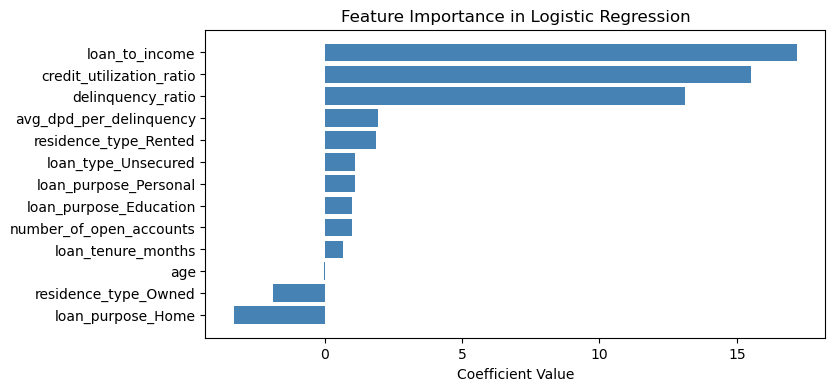

In [216]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')

plt.savefig("app/assets/feature_importance.png", 
            dpi=300, 
            bbox_inches="tight")
plt.show()

### Exporting model

In [217]:
X_test_encoded.head(2)

,number_of_open_accounts,credit_utilization_ratio,age,loan_tenure_months,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
33553,0.333,0.121,0.346,0.528,0.258,0.043,0.900,True,False,True,False,False,False
9427,1.000,0.859,0.288,0.623,0.690,0.000,0.000,True,False,False,True,False,False


In [218]:
X_test_encoded.columns

Index(['number_of_open_accounts', 'credit_utilization_ratio', 'age',
       'loan_tenure_months', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='object')

In [219]:
cols_to_scale

Index(['number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'age', 'number_of_dependants',
       'years_at_current_address', 'sanction_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='object')

In [220]:
X_train_encoded.columns

Index(['number_of_open_accounts', 'credit_utilization_ratio', 'age',
       'loan_tenure_months', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='object')

In [222]:
from joblib import dump

model_data = {
    'model': final_model,
    'features': X_train_encoded.columns,
    'scaler': scaler,
    'cols_to_scale': cols_to_scale
}
dump(model_data, 'artifacts/model_data.joblib')

FileNotFoundError: [Errno 2] No such file or directory: 'artifacts/model_data.joblib'